# Association Rules
## Venta cruzada de servicios de telecomunicaciones

---



Con esta base de datos cada cliente es una **"cesta"** de servicios.

El objetivo es doble:

- **Analizar qué servicios tienen la relación de contratación más fuerte** entre sí.
- **Identificar oportunidades de venta cruzada** a partir del servicio más contratado.

> **Valor de negocio:** si descubrimos que quien contrata "líneas múltiples" suele añadir "streaming", podemos (1) crear **packs** con precio atractivo, (2) **recomendar** el segundo servicio y (3) ajustar el **pricing** de los servicios ancla.

### Estructura del notebook

| # | Sección | Contenido |
|---|---------|-----------|
| 1 | Carga de los datos | Lectura del fichero de clientes |
| 2 | Explicación de variables | Qué representa cada servicio |
| 3 | Preprocesamiento | One-Hot + Label Encoding a formato binario 0/1 |
| 4 | Algoritmo Apriori | Frecuencia de contratación (*support*) |
| 5 | Reglas de asociación | Confianza y *Lift* entre servicios |
| 6 | Estrategia de producto | Traducción a acciones comerciales |
| 7 | Preguntas de la actividad | Respuesta razonada a las 5 preguntas |


# 1.- Carga de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

In [3]:
# Ruta relativa desde notebooks/ hacia data/raw/
DATA_PATH = '../data/raw/ChurnData_grupoA.csv'
df = pd.read_csv(DATA_PATH)
print(f"Dataset cargado: {df.shape[0]:,} clientes x {df.shape[1]} columnas")
df.head()

Dataset cargado: 1,763 clientes x 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,6574-MCOEH,Female,0,Yes,Yes,33,Yes,Yes,DSL,No,...,Yes,Yes,Yes,Yes,One year,Yes,Electronic check,79.15,2531.4,No
1,7399-QHBJS,Female,0,Yes,Yes,72,Yes,Yes,DSL,Yes,...,No,Yes,No,No,Two year,No,Credit card (automatic),66.75,4760.3,No
2,3049-SOLAY,Female,0,Yes,No,3,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.20,292.85,Yes
3,0997-YTLNY,Female,0,No,Yes,19,Yes,No,DSL,No,...,No,Yes,No,No,Month-to-month,No,Mailed check,48.80,953.65,No
4,3317-HRTNN,Female,1,No,No,5,No,No phone service,DSL,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,45.70,198,Yes


# 2.- Explicación de variables

Cada fila es un **cliente** y las columnas describen sus datos y los **servicios contratados**. En este caso hay que prestar especial atención a los servicios (los "productos" de nuestra cesta).

**Datos del cliente (para segmentar, no son "productos"):**
- *customerID*: identificador único (no entra en el modelo).
- *gender*: género (Male/Female).
- *SeniorCitizen*: si es cliente sénior (0/1).
- *Partner*: si tiene pareja (Yes/No).
- *Dependents*: si tiene personas a cargo (Yes/No).
- *tenure*: meses de antigüedad.
- *Contract*, *PaperlessBilling*, *PaymentMethod*, *MonthlyCharges*, *TotalCharges*, *Churn*: contrato, facturación y abandono.

**Servicios contratados (otra vez, son los "productos" de nuestra cesta):**
- *PhoneService*: servicio de telefonía (Yes/No).
- *MultipleLines*: líneas telefónicas múltiples (Yes/No/No phone service).
- *InternetService*: tipo de internet (Fiber optic/DSL/No) variable con **3 categorías**.
- *OnlineSecurity*: seguridad online.
- *OnlineBackup*: copia de seguridad en la nube.
- *DeviceProtection*: protección de dispositivos.
- *TechSupport*: soporte técnico premium.
- *StreamingTV*: streaming de televisión.
- *StreamingMovies*: streaming de películas.

> Los servicios de internet aparecen como *"No internet service"* cuando el cliente no tiene internet, y *MultipleLines* como *"No phone service"* cuando no tiene telefonía. Ambos los trataremos como **"No contratado" (0)**.


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1763 entries, 0 to 1762
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        1763 non-null   object 
 1   gender            1763 non-null   object 
 2   SeniorCitizen     1763 non-null   int64  
 3   Partner           1763 non-null   object 
 4   Dependents        1763 non-null   object 
 5   tenure            1763 non-null   int64  
 6   PhoneService      1763 non-null   object 
 7   MultipleLines     1763 non-null   object 
 8   InternetService   1763 non-null   object 
 9   OnlineSecurity    1763 non-null   object 
 10  OnlineBackup      1763 non-null   object 
 11  DeviceProtection  1763 non-null   object 
 12  TechSupport       1763 non-null   object 
 13  StreamingTV       1763 non-null   object 
 14  StreamingMovies   1763 non-null   object 
 15  Contract          1763 non-null   object 
 16  PaperlessBilling  1763 non-null   object 


# 3.- Preprocesamiento y limpieza de variables

Definimos primero la lista de servicios (nuestra cesta):


In [5]:
servicios = ['PhoneService', 'MultipleLines', 'InternetService',
             'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
             'TechSupport', 'StreamingTV', 'StreamingMovies']

# Frecuencia de cada valor en cada servicio
for col in servicios:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- PhoneService ---
PhoneService
Yes    1571
No      192
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  857
Yes                 714
No phone service    192
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    771
DSL            620
No             372
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     887
Yes                    504
No internet service    372
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No                     787
Yes                    604
No internet service    372
Name: count, dtype: int64

--- DeviceProtection ---
DeviceProtection
No                     799
Yes                    592
No internet service    372
Name: count, dtype: int64

--- TechSupport ---
TechSupport
No                     861
Yes                    530
No internet service    372
Name: count, dtype: int64

--- StreamingTV ---
StreamingTV
No                     717
Yes                

Vemos que casi todas las variables son binarias (Yes/No) salvo dos matices:

- **`InternetService`** tiene **3 categorías** (Fiber optic / DSL / No) aquí usamos el **One-Hot Encoding**.
- Servicios con *"No internet service"* o *"No phone service"* equivalen a **No contratado (0)**.

Para nuestro algoritmo será así: **valor 1 = servicio contratado**, **valor 0 = no contratado**.


## 3.1.- One-Hot Encoder

Aquí lo aplicamos con: `InternetService` con tres valores posibles (*Fiber optic*, *DSL*, *No*).


In [6]:
# One-Hot Encoding sobre la variable categórica real 'InternetService'
encoder = pd.get_dummies(df['InternetService'], prefix='Internet').astype(int)

print("One-Hot Encoding sobre 'InternetService':")
encoder.head(8)

One-Hot Encoding sobre 'InternetService':


,Internet_DSL,Internet_Fiber optic,Internet_No
0,1,0,0
1,1,0,0
2,0,1,0
3,1,0,0
4,1,0,0
5,1,0,0
6,0,1,0
7,0,0,1


> Para el análisis de cesta nos basta con saber **si el cliente tiene internet o no**, así que a continuación reducimos `InternetService` a una única columna binaria (1 = tiene internet, 0 = no).


## 3.2.- Label Encoder

El **Label Encoding** convierte etiquetas de texto en números. Aquí transformamos todos los `Yes` en `1` y todo lo demás (`No`, `No phone service`, `No internet service`) en `0`.


In [7]:
# Construimos la matriz binaria de servicios (la "cesta" de cada cliente)
cesta = pd.DataFrame(index=df.index)

for col in servicios:
    if col == 'InternetService':
        # 1 si tiene cualquier internet (Fiber optic o DSL), 0 si 'No'
        cesta[col] = (df[col] != 'No').astype(int)
    else:
        # 1 solo si el valor es exactamente 'Yes'
        cesta[col] = (df[col] == 'Yes').astype(int)

cesta.head()

,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,1,1,1,0,0,1,1,1,1
1,1,1,1,1,1,0,1,0,0
2,1,1,1,0,0,0,0,1,1
3,1,0,1,0,0,0,1,0,0
4,0,0,1,0,0,0,0,1,1


In [8]:
# Comprobamos que todas las variables tienen clases (no son todo 0 ni todo 1)
for col in cesta.columns:
    n_unique = cesta[col].nunique()
    pct_1 = cesta[col].mean() * 100
    print(f"{col}: {n_unique} clases | {pct_1:.1f}% contratado")

PhoneService: 2 clases | 89.1% contratado
MultipleLines: 2 clases | 40.5% contratado
InternetService: 2 clases | 78.9% contratado
OnlineSecurity: 2 clases | 28.6% contratado
OnlineBackup: 2 clases | 34.3% contratado
DeviceProtection: 2 clases | 33.6% contratado
TechSupport: 2 clases | 30.1% contratado
StreamingTV: 2 clases | 38.2% contratado
StreamingMovies: 2 clases | 38.0% contratado


Todas las variables tienen ceros y unos (ninguna está contratada por el 0% ni el 100%), así que todas aportan posibles combinaciones.



# 4.- Algoritmo de frecuencia de contratación (Apriori)

El algoritmo **Apriori** identifica los **itemsets frecuentes**: combinaciones de servicios que aparecen juntas por encima de un umbral mínimo.

La métrica clave es el **support (soporte)**:

> **Support de un itemset** = (nº de clientes que contienen ese conjunto de servicios) / (total de clientes)

Es decir, **la frecuencia relativa**. Usaremos un soporte mínimo del 15% para quedarnos con las combinaciones relevantes.


In [9]:
# Apriori necesita datos booleanos
cesta_bool = cesta.astype(bool)

# Lanzamiento del modelo con soporte mínimo del 15%
itemsets = apriori(
    cesta_bool,
    min_support=0.15,
    use_colnames=True
)

# Relación de itemsets ordenados por frecuencia
itemsets.sort_values(by='support', ascending=False).head(15)

,support,itemsets
0,0.891095,(PhoneService)
2,0.788996,(InternetService)
10,0.680091,"(InternetService, PhoneService)"
1,0.404991,(MultipleLines)
9,0.404991,"(MultipleLines, PhoneService)"
7,0.382303,(StreamingTV)
26,0.382303,"(StreamingTV, InternetService)"
8,0.380034,(StreamingMovies)
27,0.380034,"(StreamingMovies, InternetService)"
40,0.363018,"(InternetService, MultipleLines, PhoneService)"


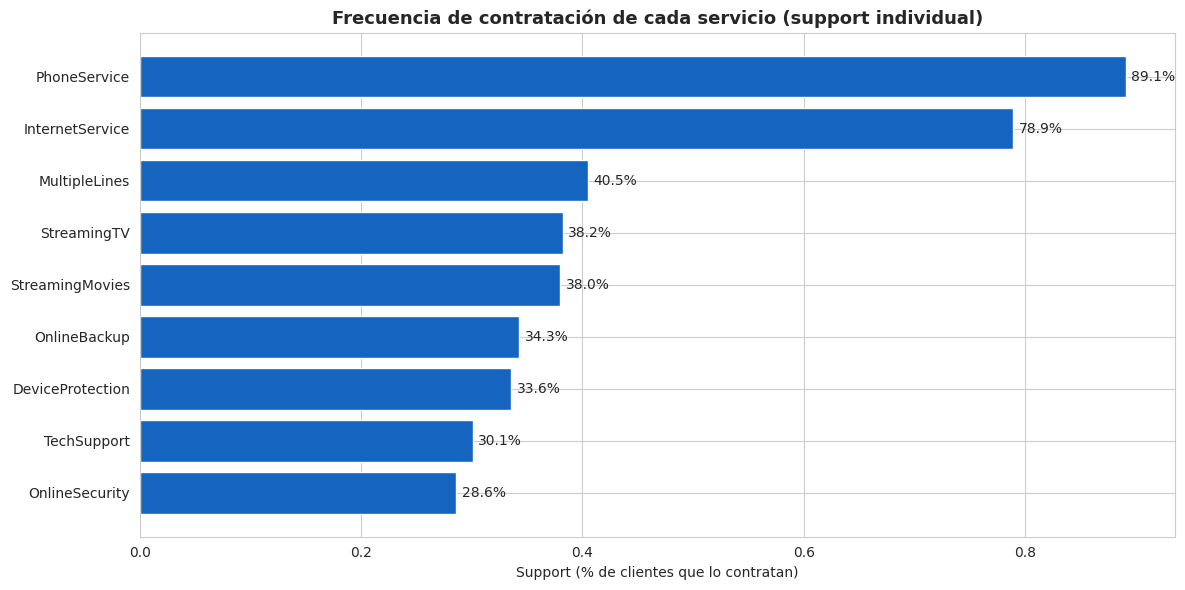

El servicio más contratado es: PhoneService


In [10]:
# Soporte de los servicios individuales (itemsets de 1 solo item)
itemsets['n_items'] = itemsets['itemsets'].apply(lambda x: len(x))
individuales = itemsets[itemsets['n_items'] == 1].copy()
individuales['servicio'] = individuales['itemsets'].apply(lambda x: list(x)[0])
individuales = individuales.sort_values('support', ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(individuales['servicio'], individuales['support'], color='#1565C0', edgecolor='white')
for bar, val in zip(bars, individuales['support']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2, f'{val*100:.1f}%',
            va='center', fontsize=10)
ax.set_title('Frecuencia de contratación de cada servicio (support individual)', fontsize=13, fontweight='bold')
ax.set_xlabel('Support (% de clientes que lo contratan)')
plt.tight_layout()
plt.show()

servicio_top = individuales.iloc[-1]['servicio']
print(f"El servicio más contratado es: {servicio_top}")

`PhoneService`, `InternetService` son los itemsets más frecuentes.
Una vez identificados los itemsets frecuentes, ahora debemos aplicar **filtros**:

- Itemsets de un **tamaño mínimo** (2 o más servicios para venta cruzada).
- Itemsets que contienen un **ítem determinado** (para estudiar un servicio concreto).


## 4.1.- Patrones de contratación de tamaño mínimo

Sirve para identificar la **venta cruzada**: los servicios que se contratan juntos.


In [11]:
# Top 10 itemsets con al menos 2 servicios, ordenados por soporte
itemsets_multi = itemsets.query('n_items >= 2').sort_values('support', ascending=False).head(10).copy()
itemsets_multi['combo'] = itemsets_multi['itemsets'].apply(lambda x: ' + '.join(sorted(x)))

print("Top 10 combinaciones de servicios más frecuentes:")
itemsets_multi[['combo', 'support', 'n_items']].reset_index(drop=True)

Top 10 combinaciones de servicios más frecuentes:


,combo,support,n_items
0,InternetService + PhoneService,0.680091,2
1,MultipleLines + PhoneService,0.404991,2
2,InternetService + StreamingTV,0.382303,2
3,InternetService + StreamingMovies,0.380034,2
4,InternetService + MultipleLines + PhoneService,0.363018,3
5,InternetService + MultipleLines,0.363018,2
6,InternetService + OnlineBackup,0.342598,2
7,InternetService + PhoneService + StreamingTV,0.337493,3
8,PhoneService + StreamingTV,0.337493,2
9,DeviceProtection + InternetService,0.335791,2


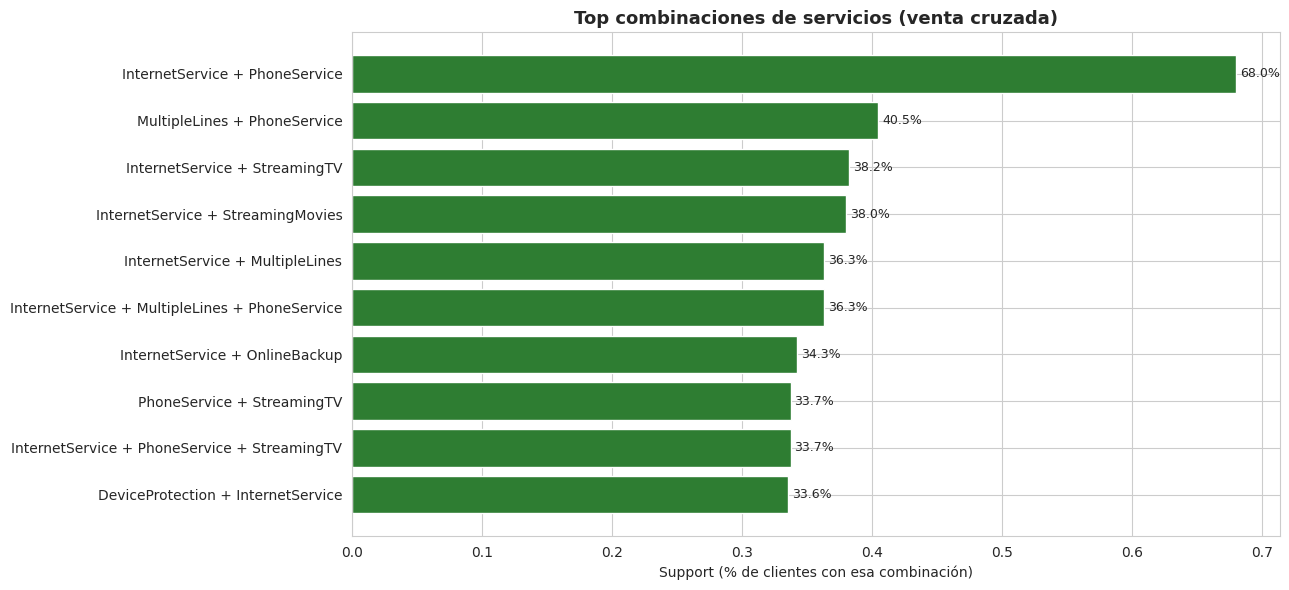

In [12]:
# Visualizamos las combinaciones más frecuentes
fig, ax = plt.subplots(figsize=(13, 6))
combos = itemsets_multi.sort_values('support')
bars = ax.barh(combos['combo'], combos['support'], color='#2E7D32', edgecolor='white')
for bar, val in zip(bars, combos['support']):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2, f'{val*100:.1f}%',
            va='center', fontsize=9)
ax.set_title('Top combinaciones de servicios (venta cruzada)', fontsize=13, fontweight='bold')
ax.set_xlabel('Support (% de clientes con esa combinación)')
plt.tight_layout()
plt.show()

Todas las combinaciones contienen al menos `PhoneService`, `InternetService` o ambos. Lo que confirma que estos son los más importantes para este caso.

## 4.2.- Patrones de contratación con un servicio determinado

Identificado el servicio más contratado, queremos ver **qué otros servicios se llevan los clientes que lo contratan**. Es la base de la venta cruzada y las promociones.


In [13]:
# Itemsets frecuentes que contienen el servicio más popular
mask = itemsets['itemsets'].map(lambda x: servicio_top in x)
itemsets_ancla = itemsets.loc[mask].sort_values(by='support', ascending=False).copy()
itemsets_ancla['combo'] = itemsets_ancla['itemsets'].apply(lambda x: ' + '.join(sorted(x)))

print(f"Itemsets frecuentes que contienen '{servicio_top}':")
itemsets_ancla[['combo', 'support', 'n_items']].reset_index(drop=True)

Itemsets frecuentes que contienen 'PhoneService':


,combo,support,n_items
0,PhoneService,0.891095,1
1,InternetService + PhoneService,0.680091,2
2,MultipleLines + PhoneService,0.404991,2
3,InternetService + MultipleLines + PhoneService,0.363018,3
4,InternetService + PhoneService + StreamingTV,0.337493,3
5,PhoneService + StreamingTV,0.337493,2
6,PhoneService + StreamingMovies,0.332955,2
7,InternetService + PhoneService + StreamingMovies,0.332955,3
8,InternetService + OnlineBackup + PhoneService,0.301191,3
9,OnlineBackup + PhoneService,0.301191,2


# 5.- Algoritmo de reglas de asociación

El Apriori nos dijo **qué se contrata junto**. Las **reglas de asociación** van un paso más allá: establecen relaciones dirigidas **"si... entonces..."**.

> *"Dado que este cliente ha contratado el servicio A (antecedente), es muy probable que también contrate el servicio B (consecuente)."*

Métricas clave:

| Métrica | Qué mide | Lectura de negocio |
|---------|----------|--------------------|
| **Support** | Frecuencia de la combinación A+B | ¿Cómo de común es este patrón? |
| **Confidence** | P(B \| A): si contrata A, probabilidad de que contrate B | Fiabilidad de la recomendación |
| **Lift** | Cuánto más probable es B con A que sin A | > 1 = asociación positiva (candidato a pack) |


In [14]:
# Crear reglas de asociación con confianza mínima del 50%
confianza = 0.5

reglas = association_rules(
    itemsets,                     # itemsets del Apriori anterior
    metric="confidence",
    min_threshold=confianza,
    num_itemsets=len(cesta_bool)  # nº total de clientes (transacciones)
)

print(f"Número de reglas generadas: {len(reglas)}")
print(f"Confianza mínima: {reglas['confidence'].min():.3f}")
print(f"Confianza máxima: {reglas['confidence'].max():.3f}")
print(f"Lift máximo: {reglas['lift'].max():.3f}")

# Formateamos antecedentes y consecuentes para leerlos bien
reglas['antecedente'] = reglas['antecedents'].apply(lambda x: ' + '.join(sorted(x)))
reglas['consecuente'] = reglas['consequents'].apply(lambda x: ' + '.join(sorted(x)))

reglas[['antecedente', 'consecuente', 'support', 'confidence', 'lift']].sort_values(
    by='lift', ascending=False).head(10).reset_index(drop=True)

Número de reglas generadas: 320
Confianza mínima: 0.500
Confianza máxima: 1.000
Lift máximo: 2.243


,antecedente,consecuente,support,confidence,lift
0,MultipleLines + StreamingTV,PhoneService + StreamingMovies,0.162223,0.746736,2.242753
1,InternetService + MultipleLines + StreamingTV,PhoneService + StreamingMovies,0.162223,0.746736,2.242753
2,MultipleLines + StreamingTV,InternetService + PhoneService + StreamingMovies,0.162223,0.746736,2.242753
3,MultipleLines + StreamingMovies,InternetService + PhoneService + StreamingTV,0.162223,0.756614,2.241866
4,InternetService + MultipleLines + StreamingMovies,PhoneService + StreamingTV,0.162223,0.756614,2.241866
5,MultipleLines + StreamingMovies,PhoneService + StreamingTV,0.162223,0.756614,2.241866
6,DeviceProtection + StreamingTV,InternetService + StreamingMovies,0.166761,0.784000,2.062973
7,DeviceProtection + InternetService + StreamingTV,StreamingMovies,0.166761,0.784000,2.062973
8,DeviceProtection + StreamingTV,StreamingMovies,0.166761,0.784000,2.062973
9,DeviceProtection + StreamingMovies,InternetService + StreamingTV,0.166761,0.757732,1.982020


**Interpretación de la tabla:**

- **antecedente / consecuente:** la relación entre servicios (A → B).
- **support:** frecuencia con la que ocurre la combinación A+B.
- **confidence:** probabilidad de que, si se contrata A, también se contrate B.
- **lift:** cuánto refuerza A la contratación de B (>1 = relación positiva).


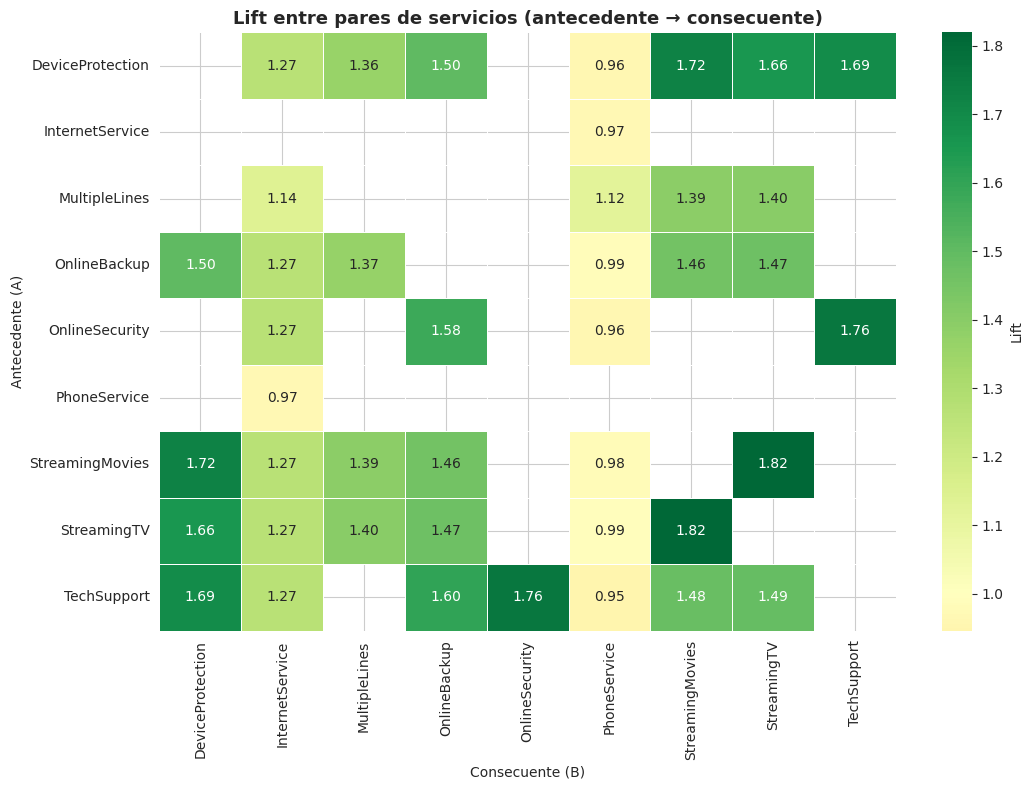

Verde intenso (lift > 1) = contratar A dispara la contratación de B: candidatos a pack.


In [15]:
# Heatmap de asociación: lift entre pares de servicios (solo reglas 1 a 1)
reglas_simples = reglas[(reglas['antecedents'].apply(len)==1) &
                        (reglas['consequents'].apply(len)==1)].copy()
reglas_simples['A'] = reglas_simples['antecedents'].apply(lambda x: list(x)[0])
reglas_simples['B'] = reglas_simples['consequents'].apply(lambda x: list(x)[0])

pivot = reglas_simples.pivot_table(index='A', columns='B', values='lift')

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn', center=1,
            linewidths=0.5, linecolor='white', cbar_kws={'label': 'Lift'}, ax=ax)
ax.set_title('Lift entre pares de servicios (antecedente → consecuente)', fontsize=13, fontweight='bold')
ax.set_xlabel('Consecuente (B)')
ax.set_ylabel('Antecedente (A)')
plt.tight_layout()
plt.show()

print("Verde intenso (lift > 1) = contratar A dispara la contratación de B: candidatos a pack.")

# 6.- Estrategia de Producto

Con las reglas anteriores diseñamos **estrategias comerciales concretas**: elegimos las relaciones más fuertes y construimos sobre ellas packs, recomendaciones y ajustes de precio.


In [16]:
# Las 5 reglas más fuertes por lift
top_reglas = reglas.sort_values(by='lift', ascending=False).head(5)
top_reglas[['antecedente', 'consecuente', 'support', 'confidence', 'lift']].reset_index(drop=True)

,antecedente,consecuente,support,confidence,lift
0,MultipleLines + StreamingTV,PhoneService + StreamingMovies,0.162223,0.746736,2.242753
1,InternetService + MultipleLines + StreamingTV,PhoneService + StreamingMovies,0.162223,0.746736,2.242753
2,MultipleLines + StreamingTV,InternetService + PhoneService + StreamingMovies,0.162223,0.746736,2.242753
3,MultipleLines + StreamingMovies,InternetService + PhoneService + StreamingTV,0.162223,0.756614,2.241866
4,InternetService + MultipleLines + StreamingMovies,PhoneService + StreamingTV,0.162223,0.756614,2.241866


In [17]:
# Resumen accionable: convertimos cada regla en una recomendación de negocio
print("="*70)
print("RECOMENDACIONES DE VENTA CRUZADA (ordenadas por fuerza de asociación)")
print("="*70)
for i, (_, row) in enumerate(top_reglas.iterrows(), start=1):
    print(f"\n{i}. Cliente que contrata [{row['antecedente']}]")
    print(f"   -> Ofrecer: [{row['consecuente']}]")
    print(f"   Confianza: {row['confidence']*100:.0f}% de acierto | Lift: {row['lift']:.2f}x | Cobertura: {row['support']*100:.1f}% de clientes")

RECOMENDACIONES DE VENTA CRUZADA (ordenadas por fuerza de asociación)

1. Cliente que contrata [MultipleLines + StreamingTV]
   -> Ofrecer: [PhoneService + StreamingMovies]
   Confianza: 75% de acierto | Lift: 2.24x | Cobertura: 16.2% de clientes

2. Cliente que contrata [InternetService + MultipleLines + StreamingTV]
   -> Ofrecer: [PhoneService + StreamingMovies]
   Confianza: 75% de acierto | Lift: 2.24x | Cobertura: 16.2% de clientes

3. Cliente que contrata [MultipleLines + StreamingTV]
   -> Ofrecer: [InternetService + PhoneService + StreamingMovies]
   Confianza: 75% de acierto | Lift: 2.24x | Cobertura: 16.2% de clientes

4. Cliente que contrata [MultipleLines + StreamingMovies]
   -> Ofrecer: [InternetService + PhoneService + StreamingTV]
   Confianza: 76% de acierto | Lift: 2.24x | Cobertura: 16.2% de clientes

5. Cliente que contrata [InternetService + MultipleLines + StreamingMovies]
   -> Ofrecer: [PhoneService + StreamingTV]
   Confianza: 76% de acierto | Lift: 2.24x | Co

> **Las reglas de asociación no predicen el futuro, revelan la estructura oculta de la demanda.** Convierten un histórico de contrataciones en un mapa de oportunidades de ingreso incremental, para afianzar estrategias de producto de forma descriptiva.

Pero se ve un poco confuso. Modifiquemos un poco las reglas para evitar redundancias para hacer las cosas menos confusas.



In [18]:
# Quitamos PhoneService e InternetService del análisis de reglas de asociación:
# son "servicios base" que casi cualquier addon arrastra estructuralmente
# (p. ej. nadie tiene MultipleLines sin PhoneService, ni StreamingTV sin
# InternetService). Si los dejamos, generan reglas "clon" con el mismo
# support/confidence/lift que no aportan información nueva.
cesta_reglas = cesta.drop(columns=['PhoneService', 'InternetService'])
cesta_reglas_bool = cesta_reglas.astype(bool)

items_reglas = apriori(cesta_reglas_bool, min_support=0.15, use_colnames=True)

confianza = 0.5
reglas = association_rules(
    items_reglas,
    metric="confidence",
    min_threshold=confianza,
    num_itemsets=len(cesta_reglas_bool)
)

reglas['antecedente'] = reglas['antecedents'].apply(lambda x: ' + '.join(sorted(x)))
reglas['consecuente'] = reglas['consequents'].apply(lambda x: ' + '.join(sorted(x)))

print(f"Número de reglas generadas: {len(reglas)}")
reglas[['antecedente', 'consecuente', 'support', 'confidence', 'lift']].sort_values(
    by='lift', ascending=False).reset_index(drop=True)

Número de reglas generadas: 32


,antecedente,consecuente,support,confidence,lift
0,DeviceProtection + StreamingTV,StreamingMovies,0.166761,0.784000,2.062973
1,DeviceProtection + StreamingMovies,StreamingTV,0.166761,0.757732,1.982020
2,MultipleLines + StreamingMovies,StreamingTV,0.162223,0.756614,1.979095
3,MultipleLines + StreamingTV,StreamingMovies,0.162223,0.746736,1.964920
4,StreamingMovies + StreamingTV,DeviceProtection,0.166761,0.630901,1.878850
5,StreamingMovies,StreamingTV,0.264322,0.695522,1.819297
6,StreamingTV,StreamingMovies,0.264322,0.691395,1.819297
7,TechSupport,OnlineSecurity,0.151446,0.503774,1.762208
8,OnlineSecurity,TechSupport,0.151446,0.529762,1.762208
9,StreamingMovies,DeviceProtection,0.220079,0.579104,1.724597


In [19]:
# Las 5 reglas más fuertes por lift
top_reglas = reglas.sort_values(by='lift', ascending=False).head(5)
top_reglas[['antecedente', 'consecuente', 'support', 'confidence', 'lift']].reset_index(drop=True)

,antecedente,consecuente,support,confidence,lift
0,DeviceProtection + StreamingTV,StreamingMovies,0.166761,0.784000,2.062973
1,DeviceProtection + StreamingMovies,StreamingTV,0.166761,0.757732,1.982020
2,MultipleLines + StreamingMovies,StreamingTV,0.162223,0.756614,1.979095
3,MultipleLines + StreamingTV,StreamingMovies,0.162223,0.746736,1.964920
4,StreamingMovies + StreamingTV,DeviceProtection,0.166761,0.630901,1.878850


In [20]:
# Resumen accionable: convertimos cada regla en una recomendación de negocio
print("="*70)
print("RECOMENDACIONES DE VENTA CRUZADA (ordenadas por fuerza de asociación)")
print("="*70)
for i, (_, row) in enumerate(top_reglas.iterrows(), start=1):
    print(f"\n{i}. Cliente que contrata [{row['antecedente']}]")
    print(f"   -> Ofrecer: [{row['consecuente']}]")
    print(f"   Confianza: {row['confidence']*100:.0f}% de acierto | Lift: {row['lift']:.2f}x | Cobertura: {row['support']*100:.1f}% de clientes")

RECOMENDACIONES DE VENTA CRUZADA (ordenadas por fuerza de asociación)

1. Cliente que contrata [DeviceProtection + StreamingTV]
   -> Ofrecer: [StreamingMovies]
   Confianza: 78% de acierto | Lift: 2.06x | Cobertura: 16.7% de clientes

2. Cliente que contrata [DeviceProtection + StreamingMovies]
   -> Ofrecer: [StreamingTV]
   Confianza: 76% de acierto | Lift: 1.98x | Cobertura: 16.7% de clientes

3. Cliente que contrata [MultipleLines + StreamingMovies]
   -> Ofrecer: [StreamingTV]
   Confianza: 76% de acierto | Lift: 1.98x | Cobertura: 16.2% de clientes

4. Cliente que contrata [MultipleLines + StreamingTV]
   -> Ofrecer: [StreamingMovies]
   Confianza: 75% de acierto | Lift: 1.96x | Cobertura: 16.2% de clientes

5. Cliente que contrata [StreamingMovies + StreamingTV]
   -> Ofrecer: [DeviceProtection]
   Confianza: 63% de acierto | Lift: 1.88x | Cobertura: 16.7% de clientes


De esta forma se ve un poco más claro lo que se le debería ofrecer al cliente realmente.

# 7.- Preguntas de la actividad

A continuación respondemos, con código y datos, a las cinco preguntas planteadas.


## Pregunta 1. ¿Qué producto tiene más porcentaje de venta? ¿Tiene sentido lanzar estrategias de producto con más de un ítem?

In [21]:
# Support individual = % de clientes que contratan cada servicio
soporte_individual = (cesta.mean()*100).sort_values(ascending=False).round(1)
print("Porcentaje de venta (support individual) de cada servicio:\n")
print(soporte_individual.to_string())
print(f"\n>> Producto con MÁS porcentaje de venta: {soporte_individual.index[0]} ({soporte_individual.iloc[0]}%)")

Porcentaje de venta (support individual) de cada servicio:

PhoneService        89.1
InternetService     78.9
MultipleLines       40.5
StreamingTV         38.2
StreamingMovies     38.0
OnlineBackup        34.3
DeviceProtection    33.6
TechSupport         30.1
OnlineSecurity      28.6

>> Producto con MÁS porcentaje de venta: PhoneService (89.1%)


- El producto más vendido es **`PhoneService` (89% de los clientes)**, seguido de **`InternetService` (79%)**. Son los servicios "base".
- **Sí tiene sentido lanzar estrategias con más de un ítem.** El servicio ancla (telefonía) ya está contratado por casi todo el mundo, así que su recorrido de crecimiento como producto aislado es pequeño. El valor está en **combinar** ese servicio con otros de menor penetración (líneas múltiples 40%, streaming 38%, etc.): ahí es donde las reglas de asociación detectan *packs* y venta cruzada con ingreso incremental real.


## Pregunta 2. Promoción de móviles con líneas múltiples para San Valentín (Partner = Yes). ¿Tiene sentido con itemsets de tamaño 2 y soporte ≥ 30%? ¿Con qué soporte tendría sentido?

In [22]:
# Itemset de tamaño 2: {PhoneService, MultipleLines}
# Nota: MultipleLines solo puede ser 'Yes' si hay PhoneService, así que el par
# equivale prácticamente a "tener líneas múltiples".

def support_par(sub, a='PhoneService', c='MultipleLines'):
    return ((sub[a]==1) & (sub[c]==1)).mean()

# Global
sup_global = support_par(cesta)

# Segmento objetivo: clientes con pareja (Partner == 'Yes')
mask_partner = (df['Partner'] == 'Yes').values
sup_partner = support_par(cesta[mask_partner])

print(f"Soporte {{PhoneService, MultipleLines}} - TODOS los clientes : {sup_global*100:.1f}%")
print(f"Soporte {{PhoneService, MultipleLines}} - Partner = Yes      : {sup_partner*100:.1f}%  (n={mask_partner.sum()})")
print(f"\nUmbral propuesto en la actividad: 30%")
print(f">> ¿Supera el 30% en el segmento Partner=Yes? {'SÍ' if sup_partner>=0.30 else 'NO'}")

Soporte {PhoneService, MultipleLines} - TODOS los clientes : 40.5%
Soporte {PhoneService, MultipleLines} - Partner = Yes      : 48.2%  (n=859)

Umbral propuesto en la actividad: 30%
>> ¿Supera el 30% en el segmento Partner=Yes? SÍ


- En el segmento **Partner = Yes**, el itemset **{PhoneService, MultipleLines}** tiene un soporte de **48%**, muy por encima del **30%** propuesto.
- Por tanto, **sí tiene sentido** lanzar la promoción con itemsets de tamaño 2 y soporte ≥ 30%: casi la mitad de los clientes con pareja ya combinan telefonía + líneas múltiples, es un patrón sólido y frecuente.
- **¿Con qué soporte tendría sentido?** Como el soporte real ronda el 48%, podríamos fijar el umbral incluso más alto, alrededor de **45–48%**, y la combinación seguiría apareciendo. Un umbral del 30% es conservador; pero poner algo por encima de 48% ya dejaría fuera esta combinación.
- *Nota importante:* como no se pueden tener "líneas múltiples" sin "telefonía", el par {PhoneService, MultipleLines} coincide con el soporte de MultipleLines. La regla es válida, pero debemos tenerlo en cuenta al interpretarla.


## Pregunta 3. ¿Tendría sentido lanzar la campaña anterior solo para hombres o solo para mujeres (gender)?

In [23]:
# Repetimos el soporte del par por género, dentro del segmento Partner = Yes
print("Soporte {PhoneService, MultipleLines} dentro de Partner = Yes, por género:\n")
for g in ['Male', 'Female']:
    m = ((df['Partner']=='Yes') & (df['gender']==g)).values
    print(f"  {g:7s} & Partner=Yes : {support_par(cesta[m])*100:5.1f}%  (n={m.sum()})")

Soporte {PhoneService, MultipleLines} dentro de Partner = Yes, por género:

  Male    & Partner=Yes :  50.7%  (n=428)
  Female  & Partner=Yes :  45.7%  (n=431)


- Hombres con pareja: **50,7%**; mujeres con pareja: **45,7%**. **Ambos superan holgadamente el 30%.**
- La diferencia entre géneros es **pequeña (5 puntos)**, así que **no compensa excluir a ninguno**: dejaríamos fuera a un grupo que también responde muy bien a la promoción.
- Si obligatoriamente hubiera que priorizar, los **hombres con pareja** muestran un soporte ligeramente superior, pero la recomendación sensata es **lanzar la campaña a todo el segmento Partner=Yes sin segmentar por género**, porque el género no discrimina de forma relevante este comportamiento de compra en esta base de datos.


## Pregunta 4. ¿Con qué otro producto se puede lanzar una promoción de teléfonos móviles?

In [24]:
# Reglas 1->1 que parten de MultipleLines (cliente "móvil avanzado"), por lift
reglas_ml = reglas_simples[reglas_simples['A']=='MultipleLines'].sort_values('lift', ascending=False)
print("Servicios que mejor acompañan a 'MultipleLines' (antecedente -> consecuente):\n")
print(reglas_ml[['A','B','support','confidence','lift']].to_string(index=False))

Servicios que mejor acompañan a 'MultipleLines' (antecedente -> consecuente):

            A               B  support  confidence     lift
MultipleLines     StreamingTV 0.217243    0.536415 1.403114
MultipleLines StreamingMovies 0.214407    0.529412 1.393064
MultipleLines InternetService 0.363018    0.896359 1.136075
MultipleLines    PhoneService 0.404991    1.000000 1.122215


- Los clientes de telefonía con **líneas múltiples** son los que más se asocian con los servicios de **streaming**: **`StreamingTV`** (confianza 53%, lift 1.40) y **`StreamingMovies`** (confianza 52%, lift 1.39) son los consecuentes con mayor *lift*.
- Es decir, el mejor **acompañante para una promoción de móviles** es un **pack de entretenimiento (streaming de TV y/o películas)**: quien contrata varias líneas tiene 1,4 veces más propensión a contratar streaming que el cliente medio.
- También aparecen, con menor fuerza, `OnlineBackup` y `DeviceProtection` (lift 1,36), útiles como segunda opción de *bundle*.


## Pregunta 5. ¿Qué estrategia de promoción de venta se puede realizar con los datos disponibles?

In [25]:
# Resumen de las mejores oportunidades de pack (packs = reglas con lift alto)
print("="*70)
print("ESTRATEGIAS DE PROMOCIÓN SUGERIDAS (basadas en lift > 1)")
print("="*70)
for i, (_, row) in enumerate(top_reglas.iterrows(), start=1):
    print(f"\n{i}. PACK: [{row['antecedente']}]  +  [{row['consecuente']}]")
    print(f"   Cobertura: {row['support']*100:.1f}% de clientes | "
          f"Acierto: {row['confidence']*100:.0f}% | Lift: {row['lift']:.2f}x")

ESTRATEGIAS DE PROMOCIÓN SUGERIDAS (basadas en lift > 1)

1. PACK: [DeviceProtection + StreamingTV]  +  [StreamingMovies]
   Cobertura: 16.7% de clientes | Acierto: 78% | Lift: 2.06x

2. PACK: [DeviceProtection + StreamingMovies]  +  [StreamingTV]
   Cobertura: 16.7% de clientes | Acierto: 76% | Lift: 1.98x

3. PACK: [MultipleLines + StreamingMovies]  +  [StreamingTV]
   Cobertura: 16.2% de clientes | Acierto: 76% | Lift: 1.98x

4. PACK: [MultipleLines + StreamingTV]  +  [StreamingMovies]
   Cobertura: 16.2% de clientes | Acierto: 75% | Lift: 1.96x

5. PACK: [StreamingMovies + StreamingTV]  +  [DeviceProtection]
   Cobertura: 16.7% de clientes | Acierto: 63% | Lift: 1.88x


Con las reglas de asociación disponibles se pueden diseñar varias estrategias de promoción **descriptivas y accionables**:

1. **Packs / bundles.** Combinar servicios con *lift* > 1 en una oferta única (p. ej. *Móvil con líneas múltiples + Streaming TV/Películas*, o *Streaming TV + Streaming Películas*), con un precio de paquete inferior a la suma por separado.
2. **Recomendador de venta cruzada ("también contratan...").** Cuando un cliente contrata el antecedente, ofrecerle automáticamente el consecuente con mayor confianza (motor de recomendación tipo *next best offer*).
3. **Pricing del servicio ancla.** Usar `PhoneService` e `InternetService` (los de mayor penetración) como gancho a precio competitivo y monetizar con los complementos asociados.
4. **Campañas segmentadas por perfil.** Aprovechar variables como `Partner`, `gender` o `SeniorCitizen` para dirigir cada pack al segmento donde el soporte es más alto (como vimos en las preguntas anteriores).
5. **Retención / anti-churn.** Como el dataset incluye `Churn`, los packs de servicios con alto *lift* pueden usarse también para **fidelizar**: más servicios contratados = mayor "coste de cambio" y menor probabilidad de abandono.

> Es importante recordar que las reglas de asociación **no predicen**, **describen** la estructura de la demanda. Son la base para decidir *qué ofrecer a quién*.
